**SAPIANS** · SCC5819 · MÓDULO 00 — A BASE SRAG · COMPARAÇÃO DE FAMÍLIAS

# Qual família prevê melhor segundo a mesma perda?

O estudo de balanceamento comparou alternativas dentro do XGBoost. Aqui
comparamos famílias com a mesma amostra de treino, a mesma avaliação temporal
e log loss como critério de escolha. Este caderno lê o registro agregado;
não inicia buscas nem altera o preditor usado nas explicações da aula.

[README do módulo](../README.md) · [protocolo](../COURSE_STUDY.md) ·
[internals](srag_sample_family_internals.ipynb)

---

**Objetivos.** Distinguir a família dos hiperparâmetros; comparar candidatos
pela mesma perda sem mudar a distribuição de avaliação; confrontar a escolha
com o histórico por ROC-AUC; ler calibração e reconhecer os limites da busca.


In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib


Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import os
import pathlib
import sys
import tempfile

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd

RANDOM_STATE = 42
REPO = pathlib.Path(os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())).resolve()
while REPO != REPO.parent and not (REPO / "tools/sapians.py").exists():
    REPO = REPO.parent
if not (REPO / "tools/sapians.py").exists():
    raise RuntimeError("Abra este caderno em um checkout do repositório.")
RECORD = pathlib.Path(os.environ.get(
    "SAPIANS_SAMPLE_FAMILY_RECORD",
    REPO / "modules/00-dataset/gold/sample_family_search.json",
)).resolve()
WORK = pathlib.Path(tempfile.mkdtemp(prefix="srag-sample-family-figures-"))
os.chdir(WORK)
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
SP.aplicar()

r = json.loads(RECORD.read_text()) if RECORD.exists() else None
protocol = r.get("protocol") if r else None
trials = r.get("validation_candidates", []) if r else []
selection = r.get("selection") if r else None
evaluation = r.get("evaluation") if r else None
status = r.get("status") if r else "absent"
if status not in {"absent", "running", "selected", "complete"}:
    raise ValueError("Estado desconhecido do registro da comparação.")
FINAL = status == "complete"
if FINAL and (not selection or not evaluation):
    raise ValueError("Registro completo sem seleção ou avaliação.")
ESTADOS = {"absent": "evidência ainda ausente", "running": "comparação em andamento",
           "selected": "seleção congelada; avaliação pendente", "complete": "comparação concluída"}
ROTULOS = {"dummy": "Constante", "lpm": "Linear em probabilidade",
           "logit": "Regressão logística", "arvore": "Árvore de decisão",
           "floresta": "Random forest", "xgb": "XGBoost"}
CURTOS = {"dummy": "Constante", "lpm": "Linear", "logit": "Logística",
          "arvore": "Árvore", "floresta": "Random forest", "xgb": "XGBoost"}
ESTILOS = {"dummy": (SP.CINZA_CLARO, "--", "x"), "lpm": (SP.CINZA, ":", "s"),
           "logit": (SP.AMBAR, "-.", "^"), "arvore": (SP.ESCURO, ":", "D"),
           "floresta": (SP.SAGE, "--", "v"), "xgb": (SP.AZUL, "-", "o")}
print("Estado:", ESTADOS[status])
print("Fonte agregada:", RECORD.name)
print("Este caderno lê evidência pública; não treina modelos nem carrega previsões individuais.")
if protocol:
    print("Versão:", protocol["version"])
    print("SHA-256 do protocolo:", protocol["protocol_sha256"])
else:
    print("Nenhum resultado é preenchido sem o registro do estudo.")


Estado: comparação concluída
Fonte agregada: sample_family_search.json
Este caderno lê evidência pública; não treina modelos nem carrega previsões individuais.
Versão: course-sample-family-logloss-v1
SHA-256 do protocolo: 636a2f169424c2a3dcc320d5c4d0bd06b18f89cb280edccd2991c5d588a5073d


## §1 — A população e o calendário permanecem

**Pergunta do modelo.** Nos registros dessa coorte, quão bem estimamos a
probabilidade do desfecho usando as informações da ficha em períodos posteriores?

A amostra de treino resulta de sorteio uniforme, sem reposição, apenas no
período de treino. Seu tamanho foi uma decisão operacional: não é cálculo de
suficiência estatística nem balanceamento. A validação e o teste contêm todos
os registros elegíveis dos respectivos períodos. Os cortes usam a data de
início dos sintomas, não uma proporção aleatória entre treino e avaliação.

Esta comparação mantém as frequências naturais das classes em todas as famílias.
Pesos, redução da classe majoritária e SMOTENC pertencem ao estudo separado
de balanceamento do XGBoost. Não extrapolamos seus resultados para outras famílias.


In [3]:
if protocol:
    particoes = []
    for split, anos, titulo in (("train", "2020–2022", "Treino amostrado"),
                                ("val", "2023", "Validação completa"),
                                ("test", "2024", "Teste completo, exploratório")):
        counts = protocol["splits"][split]
        particoes.append({"partição": titulo, "início dos sintomas": anos,
                          "registros": counts["n"], "óbitos registrados": counts.get("events", pd.NA)})
    tabela_particoes = pd.DataFrame(particoes)
    tabela_particoes["óbitos registrados"] = pd.array(tabela_particoes["óbitos registrados"], dtype="Int64")
    print(SP.tabela(tabela_particoes))
    print("Entradas brutas compartilhadas:", SP.pt_int(len(protocol["features"])))
    print("Semente registrada:", SP.pt_int(protocol["seed"]))
    print("Coorte: hospitalização E (tosse OU dor de garganta)")
    print("        E (dispneia OU baixa saturação OU desconforto respiratório).")
    print("COVID amplo: marcador PCR OU marcador de antígeno OU classificação final COVID.")
    print("Alvo: EVOLUCAO 2 = óbito registrado no caso de SRAG; 1 = cura.")
    print("EVOLUCAO 3 e códigos não admitidos são excluídos, não convertidos em cura.")
    print("Início dos sintomas >= 2020-02-26; idade das datas presente entre 0 e 120 anos.")
    print("A coorte contém registros; unicidade de pessoas não foi demonstrada.")
    print("SHA-256 da amostra:", protocol["source"]["sha256"])
else:
    print("Contagens e critérios aguardam o protocolo registrado.")


                    partição início dos sintomas registros óbitos registrados
            Treino amostrado           2020–2022   200.000             62.719
          Validação completa                2023    24.148              4.572
Teste completo, exploratório                2024    16.142                 NA
Entradas brutas compartilhadas: 40
Semente registrada: 42
Coorte: hospitalização E (tosse OU dor de garganta)
        E (dispneia OU baixa saturação OU desconforto respiratório).
COVID amplo: marcador PCR OU marcador de antígeno OU classificação final COVID.
Alvo: EVOLUCAO 2 = óbito registrado no caso de SRAG; 1 = cura.
EVOLUCAO 3 e códigos não admitidos são excluídos, não convertidos em cura.
Início dos sintomas >= 2020-02-26; idade das datas presente entre 0 e 120 anos.
A coorte contém registros; unicidade de pessoas não foi demonstrada.
SHA-256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918


**O que olhar.** A mesma informação de entrada não exige a mesma codificação.
Cada família usa o pré-processamento declarado, ajustado somente no treino.
Diferenças de desempenho descrevem esses pipelines, não uma propriedade universal
do nome do algoritmo.

## §2 — Uma busca finita, com orçamento declarado

Todos os candidatos usam classes naturais. A constante e o modelo linear de
probabilidade são referências fixas, sem grade de hiperparâmetros. As demais
famílias recebem configurações declaradas antes da execução. O orçamento
difere entre famílias e não significa igual capacidade de otimização.

O XGBoost pode reutilizar ajustes do estudo anterior se seus dados, protocolo,
parâmetros e arquivos de evidência conferirem. Reutilização auditada não é
um novo treinamento nem simples cópia de números arredondados.


In [4]:
if protocol:
    specs = protocol["candidates"]
    linhas = []
    for family in ROTULOS:
        budget = protocol["budgets"][family]
        feitos = [row for row in trials if row["family"] == family]
        reusados = sum(row.get("origin", {}).get("kind") == "imported_phase53_plain" for row in feitos)
        linhas.append({"família": ROTULOS[family], "registradas": budget,
                       "concluídas": len(feitos), "reutilizadas, auditadas": reusados,
                       "novos ajustes concluídos": len(feitos) - reusados})
    print(SP.tabela(pd.DataFrame(linhas)))
    print("Configurações no total:", SP.pt_int(len(specs)))
    print("Famílias:", SP.pt_int(len(protocol["budgets"])))
    print("Regra: menor log loss de validação sem arredondar; empate exato por identificador.")
    print("A constante e o modelo linear de probabilidade são baselines fixos.")
    print("Logística: regularização ajustável; falta de convergência impede concluir o candidato.")
    print("Árvore e floresta: profundidade e tamanho das folhas controlam a complexidade.")
    if selection:
        rf = next(row for row in selection["finalists"] if row["family"] == "floresta")
        print("Árvores fixas na random forest, sem ajuste desse número nesta grade:",
              SP.pt_int(rf["effective_params"]["n_estimators"]))
    else:
        print("Número fixo de árvores da floresta: aguardando o finalista registrado.")
    print("XGBoost: grade declarada de árvores, profundidade, taxa e regularização.")
    print("Nenhum recalibrador de probabilidades foi ajustado nesta comparação.")
else:
    print("A grade e seu orçamento não são presumidos na ausência do protocolo.")


                família registradas concluídas reutilizadas, auditadas novos ajustes concluídos
              Constante           1          1                       0                        1
Linear em probabilidade           1          1                       0                        1
    Regressão logística           7          7                       0                        7
      Árvore de decisão          24         24                       0                       24
          Random forest          10         10                       0                       10
                XGBoost          30         30                      30                        0
Configurações no total: 73
Famílias: 6
Regra: menor log loss de validação sem arredondar; empate exato por identificador.
A constante e o modelo linear de probabilidade são baselines fixos.
Logística: regularização ajustável; falta de convergência impede concluir o candidato.
Árvore e floresta: profundidade e tamanho das folha

**O que olhar.** O vencedor será a melhor configuração encontrada dentro desse
espaço. Não demonstramos que uma busca maior, outras variáveis ou outro período
preservariam o ranking. A validação participa da escolha; seu menor valor não
é uma estimativa independente do desempenho de um modelo escolhido de antemão.

## §3 — Escolher pela validação antes de comparar o teste

Primeiro escolhemos o candidato de menor log loss dentro de cada família.
Depois escolhemos entre esses finalistas, pelo mesmo critério. Os valores
da seleção não são arredondados; as tabelas de leitura são.

Log loss não é percentual de erro ou risco médio de óbito. Para cada ficha,
o cálculo penaliza a probabilidade atribuída ao desfecho que ocorreu; a média
dessas penalidades é a perda. Probabilidades muito confiantes no desfecho
contrário recebem penalidades grandes. Menor perda é melhor nesse critério.


In [5]:
modelos = []
metricas = {}
if selection:
    modelos = sorted(selection["finalists"], key=lambda row: (row["validation"]["logloss"], row["candidate_id"]))
    for row in modelos:
        metricas[(row["candidate_id"], "val")] = row["validation"]
    leitura_val = [{"família": ROTULOS[row["family"]], "log loss": row["validation"]["logloss"],
                    "ROC-AUC": row["validation"]["auc"], "Brier": row["validation"]["brier"],
                    "AP": row["validation"]["ap"], "candidato": row["candidate_id"]} for row in modelos]
    print(SP.tabela(pd.DataFrame(leitura_val), 4))
    print("Vencedor pela validação:", ROTULOS[selection["winner"]["family"]])
    print("Candidato vencedor:", selection["winner"]["candidate_id"])
    print("SHA-256 do pipeline selecionado:", selection["canonical_model"]["sha256"])
    print("O teste foi usado para selecionar:", selection["test_used_for_selection"])
else:
    print("Sem seleção congelada, candidatos parciais não recebem rótulo de vencedor.")


                família log loss ROC-AUC  Brier     AP        candidato
                XGBoost   0,4209  0,7564 0,1356 0,3817 7dcb4ad1cb16bb2d
          Random forest   0,4366  0,7379 0,1403 0,3577 be8e57d509ddcc80
      Árvore de decisão   0,4459  0,6967 0,1442 0,3026 0b2dde910767cb54
    Regressão logística   0,4644  0,7214 0,1544 0,3348 1b857d25a5f43661
Linear em probabilidade   0,5091  0,7232 0,1552 0,3371 68d02d0c9c6fee85
              Constante   0,5246  0,5000 0,1689 0,1893 0a8f093e98574dd4
Vencedor pela validação: XGBoost
Candidato vencedor: 7dcb4ad1cb16bb2d
SHA-256 do pipeline selecionado: 79469b5e9fadb661309ef8f4fece77f45b0e47afbb9270604689457cafcf0350
O teste foi usado para selecionar: False


**O que olhar.** ROC-AUC avalia a ordenação das previsões; log loss avalia as
probabilidades atribuídas aos desfechos. Uma família pode ordenar razoavelmente
bem e ainda atribuir probabilidades ruins. As métricas complementares não
substituem o critério registrado depois de vermos o resultado.

## §4 — O que acontece no período posterior

Os mesmos finalistas congelados são avaliados no período posterior. Este
teste já foi observado em estudos anteriores e sua reutilização é exploratória.
Não trocamos o vencedor da validação pelo menor valor que aparecer no teste.


                família           partição log loss ROC-AUC  Brier previsto médio observado
                XGBoost          Validação   0,4209  0,7564 0,1356         0,2209    0,1893
                XGBoost Teste exploratório   0,4090  0,7644 0,1308         0,2154    0,1824
          Random forest          Validação   0,4366  0,7379 0,1403         0,2420    0,1893
          Random forest Teste exploratório   0,4256  0,7470 0,1357         0,2376    0,1824
      Árvore de decisão          Validação   0,4459  0,6967 0,1442         0,2167    0,1893
      Árvore de decisão Teste exploratório   0,4332  0,7121 0,1396         0,2155    0,1824
    Regressão logística          Validação   0,4644  0,7214 0,1544         0,2759    0,1893
    Regressão logística Teste exploratório   0,4420  0,7255 0,1448         0,2422    0,1824
Linear em probabilidade          Validação   0,5091  0,7232 0,1552         0,2823    0,1893
Linear em probabilidade Teste exploratório   0,4978  0,7260 0,1475         0,257

figura: figures_generated/sample-family-validation-test.png


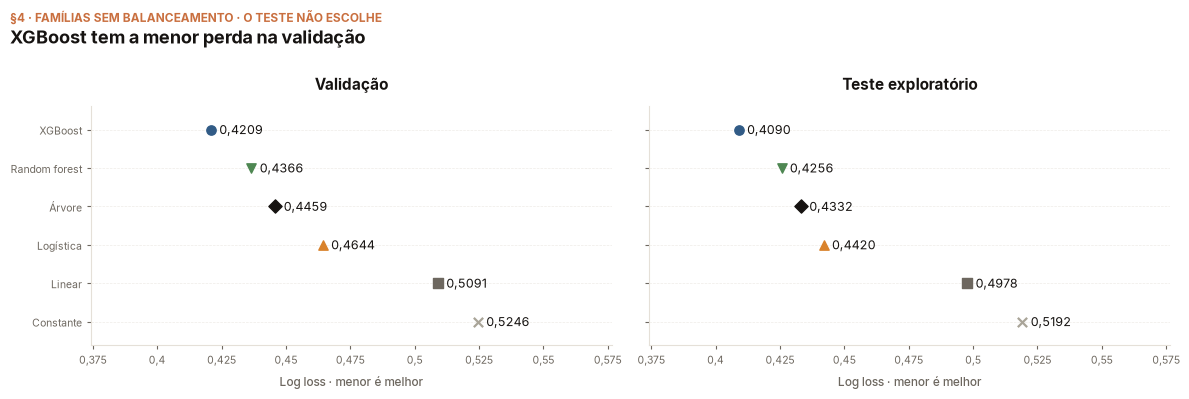

In [6]:
if FINAL:
    if evaluation["selection_changed"] or not evaluation["finalists_frozen_before_test"]:
        raise ValueError("A avaliação não preserva a seleção anterior ao teste.")
    for row in evaluation["finalists"]:
        metricas[(row["candidate_id"], "test")] = row["test"]
    linhas = []
    for row in modelos:
        for split, titulo in (("val", "Validação"), ("test", "Teste exploratório")):
            m = metricas[(row["candidate_id"], split)]
            if m["n"] != protocol["splits"][split]["n"]:
                raise ValueError("Contagem de avaliação difere da partição completa.")
            linhas.append({"família": ROTULOS[row["family"]], "partição": titulo,
                           "log loss": m["logloss"], "ROC-AUC": m["auc"], "Brier": m["brier"],
                           "previsto médio": m["mean_predicted"], "observado": m["observed"]})
    print(SP.tabela(pd.DataFrame(linhas), 4))
    fig, axes = plt.subplots(1, 2, figsize=SP.FAIXA, sharex=True, sharey=True)
    losses = [metricas[(row["candidate_id"], split)]["logloss"] for row in modelos for split in ("val", "test")]
    margem = max(0.03, (max(losses) - min(losses)) * 0.30)
    for ax, split, titulo in zip(axes, ("val", "test"), ("Validação", "Teste exploratório")):
        for i, row in enumerate(modelos):
            color, _, marker = ESTILOS[row["family"]]
            loss = metricas[(row["candidate_id"], split)]["logloss"]
            ax.scatter(loss, i, color=color, marker=marker, s=45, zorder=3)
            ax.annotate(SP.pt(loss, 4), (loss, i), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
        ax.set(title=titulo, xlabel="Log loss · menor é melhor", xlim=(min(losses) - margem, max(losses) + margem * 1.5))
        ax.set_yticks(range(len(modelos)), [CURTOS[row["family"]] for row in modelos])
        ax.margins(y=0.12)
    axes[0].invert_yaxis()
    achado = f"{ROTULOS[selection['winner']['family']]} tem a menor perda na validação"
    print(achado)
    SP.titulo(fig, achado, "§4 · FAMÍLIAS SEM BALANCEAMENTO · O TESTE NÃO ESCOLHE")
    SP.salvar(fig, "sample-family-validation-test")
    plt.show()
    plt.close(fig)
else:
    print("Tabela e figura finais aguardam a seleção e a avaliação completas.")


**O que olhar.** A escala horizontal é comum aos painéis. A ordenação dos
modelos continua sendo a da validação, facilitando perceber mudanças no teste
sem selecionar de novo.

## §5 — O que mudou em relação à escolha histórica por ROC-AUC

O estudo histórico escolhia hiperparâmetros e famílias por ROC-AUC. Esta
rodada escolhe por log loss com o pré-processamento versionado de treino.
Confrontamos os parâmetros registrados, sem apresentar diferenças entre
estudos como efeito isolado de trocar a métrica.

O modelo linear de probabilidade é um baseline ajustado por mínimos quadrados.
Suas saídas contínuas podem ultrapassar o intervalo de probabilidades e são
limitadas pela regra registrada antes de calcular a perda. Esse limite permite
avaliar o baseline, mas não demonstra que suas probabilidades sejam calibradas.


In [7]:
historico = json.loads((REPO / "modules/00-dataset/gold/selection_metrics.json").read_text())
def valor_parametro(value):
    if value is None:
        return "sem limite"
    if isinstance(value, bool):
        return str(value)
    if isinstance(value, int):
        return SP.pt_int(value)
    if isinstance(value, float):
        return SP.pt(value, 6).rstrip("0").rstrip(",")
    return str(value)

if selection:
    comparacao = []
    for row in modelos:
        antigo = historico["escolha"]["melhores"][row["family"]]
        atual = row["params"]
        chaves = sorted(set(antigo) | set(atual))
        mudancas = [f"{key}: {valor_parametro(antigo.get(key))} → {valor_parametro(atual.get(key))}"
                    for key in chaves if antigo.get(key) != atual.get(key)]
        comparacao.append({"família": ROTULOS[row["family"]], "parâmetros alterados": "; ".join(mudancas) or "mesmos parâmetros registrados"})
    print(SP.tabela(pd.DataFrame(comparacao)))
    print("Família vencedora no registro histórico por ROC-AUC:", ROTULOS[historico["escolha"]["vencedor"]])
    print("Família vencedora agora por log loss:", ROTULOS[selection["winner"]["family"]])
    print("Os valores históricos arredondados não foram usados para escolher a nova configuração.")
    print("Hiperparâmetros atuais dos finalistas:")
    for row in modelos:
        texto = "; ".join(f"{key}={valor_parametro(value)}" for key, value in sorted(row["params"].items()))
        print(f"{ROTULOS[row['family']]}: {texto or 'sem hiperparâmetros ajustados'}")
    for row in modelos:
        if row["family"] == "lpm":
            print("Regra do baseline linear: limitar as saídas a [0,000001; 0,999999] antes da perda.")
            if row.get("lpm_clip"):
                print("Diagnóstico registrado das saídas lineares na validação:")
                print(SP.tabela(pd.DataFrame([row["lpm_clip"]]), {"clip_lower": 6, "clip_upper": 6}))
else:
    print("Confronto dos parâmetros aguarda a seleção congelada.")


                família                                                                                       parâmetros alterados
                XGBoost                                                                              mesmos parâmetros registrados
          Random forest                                                         max_features: sqrt → 0,3; min_samples_leaf: 5 → 20
      Árvore de decisão ccp_alpha: 0 → 0,00001; criterion: log_loss → gini; max_depth: sem limite → 10; min_samples_leaf: 200 → 50
    Regressão logística                                                                              mesmos parâmetros registrados
Linear em probabilidade                                                                              mesmos parâmetros registrados
              Constante                                                                              mesmos parâmetros registrados
Família vencedora no registro histórico por ROC-AUC: XGBoost
Família vencedora agor

**O que olhar.** Manter os mesmos parâmetros é um resultado possível de uma
nova busca. Escolher por outra métrica não obriga o vencedor a mudar.
O registro histórico é preservado; não reescrevemos a seleção anterior.

## §6 — Calibração: olhar a curva junto das contagens

Em faixas de probabilidade de mesma largura, comparamos previsão média e
frequência observada de óbito. A diagonal indica concordância por faixa;
não significa acertar cada pessoa. A quantidade de registros em cada faixa
ajuda a interpretar pontos instáveis. Não inventamos frequência em faixa vazia.

As curvas descrevem as probabilidades avaliadas, sem recalibrador ajustado.
O desvio entre as médias globais e o ECE são diagnósticos complementares;
nenhum deles, sozinho, certifica boa calibração.


Faixas de probabilidade: 10
Validação · registros por faixa:
modelo     XGBoost Random forest Árvore Logística Linear Constante
[0,0; 0,1)   6.319         4.960  5.440     6.857  6.623         0
[0,1; 0,2)   5.228         3.560  7.453     2.821  1.884         0
[0,2; 0,3)   5.393         6.657  5.258     3.533  3.052         0
[0,3; 0,4)   4.105         6.525  3.591     3.895  4.617    24.148
[0,4; 0,5)   2.132         2.256  1.795     3.250  4.377         0
[0,5; 0,6)     762           187    567     2.226  2.513         0
[0,6; 0,7)     184             3     41     1.120    835         0
[0,7; 0,8)      25             0      3       377    203         0
[0,8; 0,9)       0             0      0        62     35         0
[0,9; 1,0]       0             0      0         7      9         0
Teste exploratório · registros por faixa:
modelo     XGBoost Random forest Árvore Logística Linear Constante
[0,0; 0,1)   4.543         3.576  3.980     5.243  5.016         0
[0,1; 0,2)   3.360        

figura: figures_generated/sample-family-calibration.png


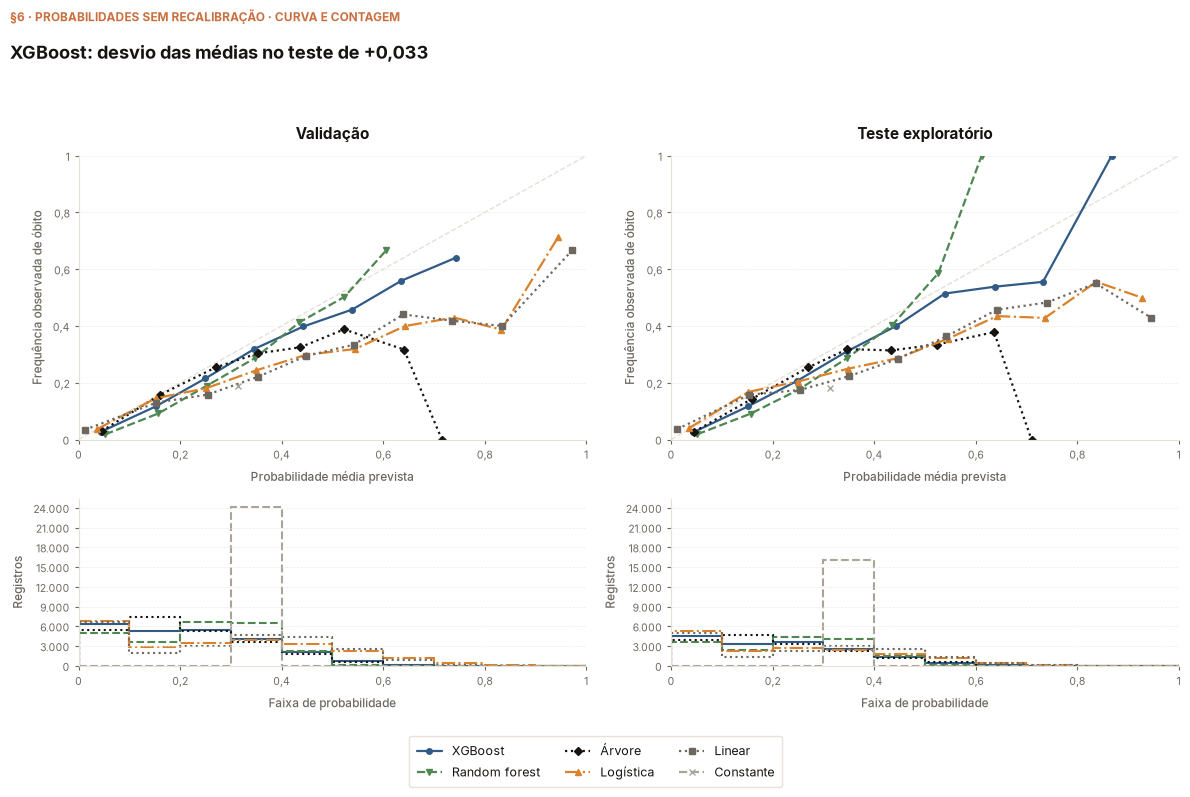

In [8]:
BORDAS = np.linspace(0, 1, 11)
calibracao = []
if FINAL:
    for row in modelos:
        for split in ("val", "test"):
            m = metricas[(row["candidate_id"], split)]
            bins = {int(b["bin"]): b for b in m["reliability"]}
            if len(bins) != len(m["reliability"]) or not set(bins).issubset(range(len(BORDAS) - 1)):
                raise ValueError("Faixas de calibração fora do contrato.")
            if sum(b["n"] for b in bins.values()) != m["n"]:
                raise ValueError("Contagens das faixas não cobrem a partição.")
            for j in range(len(BORDAS) - 1):
                b = bins.get(j)
                calibracao.append({"modelo": CURTOS[row["family"]], "candidato": row["candidate_id"],
                                   "split": split, "bin": j, "n": b["n"] if b else 0,
                                   "previsto": b["mean_predicted"] if b else np.nan,
                                   "observado": b["observed"] if b else np.nan})
    cal = pd.DataFrame(calibracao)
    print("Faixas de probabilidade:", SP.pt_int(len(BORDAS) - 1))
    for split, titulo in (("val", "Validação"), ("test", "Teste exploratório")):
        contagens = cal.loc[cal["split"] == split].pivot(index="bin", columns="modelo", values="n")
        contagens = contagens.reindex(columns=[CURTOS[row["family"]] for row in modelos])
        contagens.index = [f"[{SP.pt(BORDAS[j], 1)}; {SP.pt(BORDAS[j+1], 1)}{']' if j == len(BORDAS)-2 else ')'}" for j in contagens.index]
        print(titulo, "· registros por faixa:")
        print(SP.tabela(contagens, index=True))
    resumo = [{"família": CURTOS[row["family"]], "partição": titulo,
               "previsto médio": metricas[(row["candidate_id"], split)]["mean_predicted"],
               "observado": metricas[(row["candidate_id"], split)]["observed"],
               "desvio das médias": metricas[(row["candidate_id"], split)]["calibration_gap"],
               "ECE nas faixas": metricas[(row["candidate_id"], split)]["ece_10_equal_width"]}
              for row in modelos for split, titulo in (("val", "Validação"), ("test", "Teste exploratório"))]
    print(SP.tabela(pd.DataFrame(resumo), 4))
    fig, axes = plt.subplots(2, 2, figsize=SP.PAINEL, gridspec_kw={"height_ratios": [1.7, 1]})
    handles = []
    for coluna, (split, titulo) in enumerate((("val", "Validação"), ("test", "Teste exploratório"))):
        ax, ax_n = axes[:, coluna]
        ax.plot([0, 1], [0, 1], color=SP.LINHA, linestyle="--", linewidth=1)
        for row in modelos:
            parte = cal.loc[(cal["split"] == split) & (cal["candidato"] == row["candidate_id"])].sort_values("bin")
            color, linestyle, marker = ESTILOS[row["family"]]
            line, = ax.plot(parte["previsto"], parte["observado"], color=color, linestyle=linestyle,
                            marker=marker, markersize=4, label=CURTOS[row["family"]])
            if coluna == 0:
                handles.append(line)
            ax_n.stairs(parte["n"].to_numpy(), BORDAS, color=color, linestyle=linestyle, linewidth=1.5)
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Probabilidade média prevista", ylabel="Frequência observada de óbito", title=titulo)
        ax_n.set(xlim=(0, 1), ylim=(0, max(1, float(cal["n"].max())) * 1.05), xlabel="Faixa de probabilidade", ylabel="Registros")
        ax_n.yaxis.set_major_locator(MaxNLocator(integer=True))
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.005), ncol=3, fontsize=9)
    vencedor = selection["winner"]
    desvio = metricas[(vencedor["candidate_id"], "test")]["calibration_gap"]
    achado = f"{CURTOS[vencedor['family']]}: desvio das médias no teste de {SP.pt(desvio, 3, sinal=True)}"
    print(achado)
    SP.titulo(fig, achado, "§6 · PROBABILIDADES SEM RECALIBRAÇÃO · CURVA E CONTAGEM")
    SP.salvar(fig, "sample-family-calibration", rect=(0, 0.09, 1, 0.86))
    plt.show()
    plt.close(fig)
else:
    print("Curvas e figura finais aguardam o registro completo.")


**O que olhar.** As curvas usam as mesmas escalas; as contagens também.
Não são mostrados intervalos de confiança. Uma faixa pouco populada e um
desvio sistemático são problemas diferentes e devem ser discutidos com cuidado.

## §7 — Precisão da leitura e conclusão permitida

A tabela de auditoria conserva mais casas para conferir os valores; essa
precisão não é necessária na fala. Resultados próximos não viram empate
estatístico apenas por serem arredondados na tela.


In [9]:
if FINAL:
    auditoria = [{"família": CURTOS[row["family"]],
                  "log loss validação": metricas[(row["candidate_id"], "val")]["logloss"],
                  "log loss teste": metricas[(row["candidate_id"], "test")]["logloss"]} for row in modelos]
    print(SP.tabela(pd.DataFrame(auditoria), 8))
    print("Conclusão: nas configurações e na amostra registradas, a menor perda de validação pertence a",
          ROTULOS[selection["winner"]["family"]] + ".")
    print("O ranking não demonstra superioridade universal nem uso clínico validado.")
    print("Teste previamente observado: comparação exploratória; escolha de validação preservada.")
else:
    print("A conclusão aguarda todas as configurações e a avaliação registrada.")
print("Nenhuma migração automática: adotar outro preditor exige recalcular previsões e explicações.")


      família log loss validação log loss teste
      XGBoost         0,42090336     0,40901958
Random forest         0,43662182     0,42563533
       Árvore         0,44594492     0,43319351
    Logística         0,46435358     0,44200086
       Linear         0,50908551     0,49778675
    Constante         0,52460395     0,51920724
Conclusão: nas configurações e na amostra registradas, a menor perda de validação pertence a XGBoost.
O ranking não demonstra superioridade universal nem uso clínico validado.
Teste previamente observado: comparação exploratória; escolha de validação preservada.
Nenhuma migração automática: adotar outro preditor exige recalcular previsões e explicações.


## §8 — O que o livro diz e o que esta comparação responde

Molnar discute métodos que explicam modelos treinados. Na PFI, mantemos o
preditor fixo, permutamos uma informação da avaliação e medimos a mudança
da perda. Essa etapa não escolhe automaticamente o modelo e não exige que
as famílias anteriores tenham recebido balanceamento.

Este caderno estuda a escolha do preditor antes de explicar sua dependência
das entradas. A comparação entre famílias e o estudo de balanceamento do
XGBoost são perguntas separadas. O histórico por ROC-AUC continua preservado.

Fontes: [protocolo do módulo](../COURSE_STUDY.md),
[Molnar, PFI](https://christophm.github.io/interpretable-ml-book/feature-importance.html),
[scikit-learn, seleção e avaliação](https://scikit-learn.org/stable/modules/cross_validation.html),
[scikit-learn, escores probabilísticos](https://scikit-learn.org/stable/modules/model_evaluation.html#which-scoring-function-should-i-use) e
[scikit-learn, calibração](https://scikit-learn.org/stable/modules/calibration.html).
